# Parte 2 – Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Flujo del notebook:

1. **Línea base zero-shot** (sin entrenamiento) con `Recognai/bert-base-spanish-wwm-cased-xnli` sobre 40 titulares.
2. **Supervisión débil con LLM local** (`Qwen/Qwen2.5-3B-Instruct`, sin API ni costos) para etiquetar todo el dataset + **auditoría humana** de 20 casos.
3. **Split estratificado 70/15/15** con `random_state=42`. El test queda aislado hasta el final.
4. **Fine-tuning** de `distilbert-base-multilingual-cased` con `Trainer` de Hugging Face, optimizando **F1 macro**.
5. **Evaluación final en test**: accuracy, F1 macro y matriz de confusión.
6. **Comparativa** zero-shot vs. LLM débil vs. Transformer fine-tuned.

**Etiqueta de referencia (gold):** `etiqueta` de `datos/noticias.csv`, que viene de la sección editorial asignada por el propio diario. Todas las métricas se calculan contra ella.

In [1]:
import gc, json, time, random
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (pipeline, AutoTokenizer, AutoModelForCausalLM,
                          AutoModelForSequenceClassification, TrainingArguments, Trainer, set_seed)
from datasets import Dataset

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
CATS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
pd.set_option("display.max_colwidth", 110)

df = pd.read_csv("datos/noticias.csv").fillna({"bajada": ""})
print("Dispositivo:", DEVICE)
print("Noticias:", df.shape)
df["etiqueta"].value_counts()

W1018 19:14:04.289000 31680 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Dispositivo: mps
Noticias: (384, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    95
politica              92
Name: count, dtype: int64

## 1. Línea base zero-shot (sin fine-tuning)

Se evalúan **40 titulares** (10 por categoría, muestreo estratificado con semilla 42). El modelo compara el titular con la hipótesis *"Esta noticia trata sobre {categoría}."*.

In [2]:
ZS_MODEL = "Recognai/bert-base-spanish-wwm-cased-xnli"
zs = pipeline("zero-shot-classification", model=ZS_MODEL, device=DEVICE)

# Nombres legibles para el modelo NLI -> etiqueta oficial
ZS_LABELS = {"política": "politica", "economía": "economia", "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}

def zero_shot(textos):
    out = zs(list(textos), candidate_labels=list(ZS_LABELS), hypothesis_template="Esta noticia trata sobre {}.")
    return [ZS_LABELS[o["labels"][0]] for o in out], [o["scores"][0] for o in out]

muestra40 = df.groupby("etiqueta", group_keys=False).sample(10, random_state=SEED)
t0 = time.perf_counter()
muestra40["pred_zs"], muestra40["conf_zs"] = zero_shot(muestra40["titular"])
lat_zs = (time.perf_counter() - t0) / len(muestra40) * 1000

acc_zs40 = accuracy_score(muestra40["etiqueta"], muestra40["pred_zs"])
f1_zs40 = f1_score(muestra40["etiqueta"], muestra40["pred_zs"], average="macro")
print(f"Zero-shot (40 titulares) -> Accuracy: {acc_zs40:.3f} | F1 macro: {f1_zs40:.3f} | {lat_zs:.0f} ms/titular")
print(classification_report(muestra40["etiqueta"], muestra40["pred_zs"], zero_division=0))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot (40 titulares) -> Accuracy: 0.625 | F1 macro: 0.597 | 40 ms/titular
                    precision    recall  f1-score   support

ciencia_tecnologia       1.00      0.30      0.46        10
          deportes       0.71      1.00      0.83        10
          economia       0.67      0.40      0.50        10
          politica       0.47      0.80      0.59        10

          accuracy                           0.62        40
         macro avg       0.71      0.62      0.60        40
      weighted avg       0.71      0.62      0.60        40



In [3]:
print("Errores del zero-shot:")
muestra40.loc[muestra40["etiqueta"] != muestra40["pred_zs"], ["titular", "etiqueta", "pred_zs"]]

Errores del zero-shot:


,titular,etiqueta,pred_zs
311,Malaria y dengue: el cambio climático influye en la expansión de las dos enfermedades transmitidas por mos...,ciencia_tecnologia,deportes
361,"ChatGPT para adolescentes falla en seguridad y presenta “riesgos inaceptables”, según Common Sense Media",ciencia_tecnologia,deportes
263,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,ciencia_tecnologia,deportes
315,León XIV fue operado de cáncer de pulmón: qué implica la extirpación de un lóbulo y cómo es la recuperación,ciencia_tecnologia,politica
329,"Demetrio Pacheco, defensor ambiental en Perú: “El Estado podría haber evitado el asesinato de mi hijo” | E...",ciencia_tecnologia,politica
331,"Qué es la ""depresión sonriente"" y cómo puedes identificarla",ciencia_tecnologia,politica
334,"¡Ya güey!: Edgar, niño cuya caída se convirtió en fenómeno viral hace 20 años, se casa",ciencia_tecnologia,politica
112,"El dólar abre a la baja en S/3,42 ante debilitamiento de la divisa estadounidense",economia,politica
104,SwissCham Summit 2026: Líderes empresariales se reúnen para debatir sobre innovación e IA,economia,politica
141,De residuos y empaques a empoderamiento económico: la estrategia de sostenibilidad de Coca-Cola con tres f...,economia,politica


**Piso mínimo a superar:** el F1 macro del zero-shot sobre estos 40 titulares (impreso arriba).

## 2. Supervisión débil con un LLM local

Se usa **`Qwen/Qwen2.5-3B-Instruct`** ejecutado localmente con `transformers` (sin claves de API). El prompt es estructurado: define cada categoría, entrega el titular y la bajada, y pide responder solo con la etiqueta.

**Confianza:** en lugar de generar texto libre (que podría inventar categorías), se calcula la probabilidad que el LLM asigna a **cada una de las 4 etiquetas** como continuación de la respuesta y se normaliza con softmax. La etiqueta elegida es la más probable y `confianza` es su probabilidad. Así es imposible obtener una quinta categoría.

In [4]:
LLM_MODEL = "Qwen/Qwen2.5-3B-Instruct"
SYSTEM = """Eres un editor de un diario peruano. Clasifica cada noticia en exactamente UNA de estas categorías:
- politica: Gobierno, Presidencia, Congreso, ministros, elecciones, partidos, Fiscalía, Poder Judicial y casos de corrupción de autoridades.
- economia: mercados, empresas, empleo, precios, dólar, impuestos, AFP, pensiones, bancos, comercio y finanzas personales.
- deportes: fútbol, Liga 1, selección peruana, clubes, competencias y atletas de cualquier deporte.
- ciencia_tecnologia: tecnología, celulares, apps, internet, redes sociales, inteligencia artificial, videojuegos, espacio y ciencia.
Responde únicamente con el nombre exacto de la categoría."""

PROMPT = "Titular: {titular}\nBajada: {bajada}\n\nCategoría:"

ETIQ_LLM = Path("datos/etiquetas_llm.csv")
# Se libera el modelo zero-shot de la GPU: tenerlo cargado junto al LLM lo hace ~5 veces más lento
del zs; gc.collect(); torch.mps.empty_cache() if DEVICE == "mps" else None
llm_tok = AutoTokenizer.from_pretrained(LLM_MODEL)
llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.float16).to(DEVICE).eval()
label_ids = [llm_tok(c, add_special_tokens=False).input_ids for c in CATS]

@torch.no_grad()
def clasificar_llm(titular, bajada):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": PROMPT.format(titular=titular, bajada=bajada)}]
    p = llm_tok(llm_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True),
                add_special_tokens=False).input_ids
    seqs = [p + l for l in label_ids]
    L = max(map(len, seqs))
    ids = torch.tensor([s + [llm_tok.pad_token_id] * (L - len(s)) for s in seqs], device=DEVICE)
    mask = torch.tensor([[1] * len(s) + [0] * (L - len(s)) for s in seqs], device=DEVICE)
    k = L - len(p) + 1  # solo se calculan los logits de las posiciones de la etiqueta
    logp = llm(input_ids=ids, attention_mask=mask, logits_to_keep=k).logits.float().log_softmax(-1)
    # log P(etiqueta | prompt) = suma de log-probs de sus tokens
    scores = torch.stack([logp[i, torch.arange(len(l), device=DEVICE), torch.tensor(l, device=DEVICE)].sum()
                          for i, l in enumerate(label_ids)])
    probs = scores.softmax(0).cpu().numpy()
    return CATS[int(probs.argmax())], float(probs.max())

print(clasificar_llm("Selección peruana vence a Chile en Lima por Eliminatorias", ""))
print(clasificar_llm("BCR mantiene su tasa de referencia en 4.25%", ""))

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

('deportes', 0.9999998807907104)


('economia', 0.9999998807907104)


In [5]:
# El etiquetado completo se guarda en datos/etiquetas_llm.csv y se reutiliza si ya existe,
# para que la auditoría humana corresponda exactamente a las mismas predicciones.
if ETIQ_LLM.exists():
    etiq = pd.read_csv(ETIQ_LLM)
    print("Etiquetas LLM cargadas desde", ETIQ_LLM)
else:
    t0 = time.perf_counter()
    res = [clasificar_llm(t, b) for t, b in zip(df["titular"], df["bajada"])]
    print(f"Etiquetado en {time.perf_counter() - t0:.0f} s")
    etiq = pd.DataFrame({"titular": df["titular"],
                         "etiqueta_llm": [r[0] for r in res],
                         "confianza": [round(r[1], 4) for r in res],
                         "modelo_llm": LLM_MODEL,
                         "fecha": date.today().isoformat()})
    etiq.to_csv(ETIQ_LLM, index=False)

# Latencia del LLM medida sobre 20 noticias
t0 = time.perf_counter()
for t, b in zip(df["titular"][:20], df["bajada"][:20]):
    clasificar_llm(t, b)
lat_llm = (time.perf_counter() - t0) / 20 * 1000

params_llm = sum(p.numel() for p in llm.parameters()) / 1e6
del llm; gc.collect(); torch.mps.empty_cache() if DEVICE == "mps" else None  # libera memoria para el fine-tuning

df = df.merge(etiq[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left")
acuerdo_seccion = (df["etiqueta_llm"] == df["etiqueta"]).mean()
print(f"Filas etiquetadas: {len(etiq)} | Latencia: {lat_llm:.0f} ms/noticia")
print(f"Coincidencia LLM vs. sección editorial (todo el dataset): {acuerdo_seccion:.1%}")
etiq.head()

Etiquetas LLM cargadas desde datos/etiquetas_llm.csv


Filas etiquetadas: 384 | Latencia: 1039 ms/noticia
Coincidencia LLM vs. sección editorial (todo el dataset): 84.6%


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facultades legislativas,politica,1.0000,Qwen/Qwen2.5-3B-Instruct,2026-10-18
1,Diputados: Informe recomienda suspender por 120 días a Julián Pérez Mallqui por agresión a su expareja,politica,1.0000,Qwen/Qwen2.5-3B-Instruct,2026-10-18
2,Campañas del “No a la Revocatoria” y Reelección Municipal: Caso contra Susana Villarán se encamina a los d...,politica,1.0000,Qwen/Qwen2.5-3B-Instruct,2026-10-18
3,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,politica,0.9886,Qwen/Qwen2.5-3B-Instruct,2026-10-18
4,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas",politica,1.0000,Qwen/Qwen2.5-3B-Instruct,2026-10-18


In [6]:
print("Distribución de etiquetas del LLM:")
display(pd.crosstab(df["etiqueta"], df["etiqueta_llm"], margins=True).rename_axis(index="sección (gold)", columns="LLM"))
print("Confianza media por etiqueta LLM:")
df.groupby("etiqueta_llm")["confianza"].describe()[["mean", "min", "50%"]]

Distribución de etiquetas del LLM:


LLM,ciencia_tecnologia,deportes,economia,politica,All
sección (gold),,,,,
ciencia_tecnologia,62,6,18,9,95
deportes,0,95,1,2,98
economia,5,1,78,15,99
politica,0,0,2,90,92
All,67,102,99,116,384


Confianza media por etiqueta LLM:


,mean,min,50%
etiqueta_llm,,,
ciencia_tecnologia,0.949933,0.5562,0.9999
deportes,0.983721,0.6064,1.0000
economia,0.960431,0.5189,1.0000
politica,0.985092,0.6225,1.0000


### 2.1 Auditoría humana de 20 predicciones al azar

Se toman 20 noticias al azar (`random_state=42`) y se exportan a `datos/auditoria_humana.csv`. Una persona lee **titular y bajada**, decide si la etiqueta del LLM es correcta y anota `1` (de acuerdo) o `0` (en desacuerdo) en la columna `acuerdo_humano`, con un comentario cuando no está de acuerdo. La revisión se hace leyendo la noticia, sin mirar la sección del diario.

In [7]:
AUD = Path("datos/auditoria_humana.csv")
if not AUD.exists():
    (df.sample(20, random_state=SEED)[["titular", "bajada", "url", "etiqueta_llm", "confianza"]]
       .assign(acuerdo_humano="", comentario="")
       .to_csv(AUD, index=False))
    print("Se creó", AUD, "-> completar la columna acuerdo_humano (1/0) y volver a ejecutar.")

aud = pd.read_csv(AUD)
if aud["acuerdo_humano"].notna().all():
    n_ok = int(aud["acuerdo_humano"].sum())
    acuerdo_humano = n_ok / len(aud)
    print(f"Acuerdo LLM vs. auditoría humana: {n_ok}/{len(aud)} = {acuerdo_humano:.0%}")
else:
    n_ok, acuerdo_humano = None, None
    print("AUDITORÍA PENDIENTE")
aud[["titular", "etiqueta_llm", "confianza", "acuerdo_humano", "comentario"]]

AUDITORÍA PENDIENTE


,titular,etiqueta_llm,confianza,acuerdo_humano,comentario
0,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El C...,deportes,0.9985,NaN,NaN
1,Fabián Bustos previo al duelo ante Alianza Atlético: “El equipo va a seguir creciendo”,deportes,0.9992,NaN,NaN
2,NASA: los cuatro astronautas de Crew 12 retornaron a la tierra,ciencia_tecnologia,0.9724,NaN,NaN
3,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas,ciencia_tecnologia,1.0000,NaN,NaN
4,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en grupos del Congreso,politica,1.0000,NaN,NaN
5,Noruega estudia prohibir temporalmente las gafas inteligentes,ciencia_tecnologia,1.0000,NaN,NaN
6,Daniel Barragán cuestiona conducción de Carlos Mesía en Comisión de Constitución del Senado: “El Congreso ...,politica,1.0000,NaN,NaN
7,"De consultar saldos a delegar operaciones, ¿cómo cambiará la banca con la IA hacia 2030?",ciencia_tecnologia,0.9506,NaN,NaN
8,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",ciencia_tecnologia,1.0000,NaN,NaN
9,¡Con doblete de Lionel Messi! Inter Miami derrotó 3-1 a Atlanta United por MLS | RESUMEN Y GOLES,deportes,1.0000,NaN,NaN


## 3. Partición de datos 70 / 15 / 15

Split **estratificado** por la etiqueta gold y con `random_state=42`: primero se separa el 30%, y ese 30% se divide en mitades (validación y test). El conjunto de **test no se toca** hasta la sección 5.

**Etiqueta para entrenar:** el modelo aprende de las **etiquetas del LLM** (supervisión débil), como se plantea en el trabajo: un LLM etiqueta y un modelo pequeño aprende de él. Validación y test se miden contra la etiqueta gold de la sección, de modo que la evaluación es independiente del LLM.

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEED)

resumen = pd.DataFrame({
    "train": train_df["etiqueta"].value_counts(), "val": val_df["etiqueta"].value_counts(),
    "test": test_df["etiqueta"].value_counts()})
resumen.loc["TOTAL"] = resumen.sum()
resumen["%"] = ""
print(f"Train {len(train_df)} ({len(train_df)/len(df):.0%}) | Val {len(val_df)} ({len(val_df)/len(df):.0%}) | Test {len(test_df)} ({len(test_df)/len(df):.0%})")
assert set(train_df.url).isdisjoint(test_df.url) and set(val_df.url).isdisjoint(test_df.url)
resumen.drop(columns="%")

Train 268 (70%) | Val 58 (15%) | Test 58 (15%)


,train,val,test
etiqueta,,,
ciencia_tecnologia,66,14,15
deportes,69,15,14
economia,69,15,15
politica,64,14,14
TOTAL,268,58,58


## 4. Fine-tuning de `distilbert-base-multilingual-cased`

- Entrada: **solo el titular** (igual que en el probador del dashboard, donde el usuario escribe un titular).
- `Trainer` de Hugging Face, **3 épocas**, batch size 8, evaluación por época y selección del mejor modelo por **F1 macro** en validación.
- El modelo final se guarda en `modelo/`. Los pesos (`.safetensors`) quedan fuera de Git por tamaño; se versionan la configuración, el tokenizer y las métricas.

In [9]:
FT_MODEL = "distilbert/distilbert-base-multilingual-cased"
LABEL2ID = {c: i for i, c in enumerate(CATS)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}

tok = AutoTokenizer.from_pretrained(FT_MODEL)

def a_dataset(d, col_etiqueta):
    ds = Dataset.from_dict({"text": d["titular"].tolist(), "label": d[col_etiqueta].map(LABEL2ID).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

ds_train = a_dataset(train_df, "etiqueta_llm")   # supervisión débil
ds_val = a_dataset(val_df, "etiqueta")           # gold
ds_test = a_dataset(test_df, "etiqueta")         # gold, aislado

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "f1_macro": f1_score(p.label_ids, preds, average="macro")}

model = AutoModelForSequenceClassification.from_pretrained(
    FT_MODEL, num_labels=len(CATS), id2label=ID2LABEL, label2id=LABEL2ID)

args = TrainingArguments(
    output_dir="resultados_trainer", num_train_epochs=3,
    per_device_train_batch_size=8, per_device_eval_batch_size=16,
    learning_rate=5e-5, weight_decay=0.01, warmup_steps=10,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
    logging_strategy="epoch", report_to="none", seed=SEED)

trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tok, compute_metrics=compute_metrics)
t0 = time.perf_counter()
trainer.train()
print(f"Entrenamiento: {time.perf_counter() - t0:.0f} s en {DEVICE}")

Map:   0%|          | 0/268 [00:00<?, ? examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

/Users/isabellaalbarran/Documents/Github/python-qlab/tarea_1/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/isabellaalbarran/Documents/Github/python-qlab/tarea_1/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento: 33 s en mps


In [10]:
hist = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
hist[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3)

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.636,0.845,0.850
1,2.0,0.414,0.879,0.882
2,3.0,0.402,0.845,0.838


In [11]:
trainer.save_model("modelo")
tok.save_pretrained("modelo")
print(sorted(p.name for p in Path("modelo").iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['.gitkeep', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el conjunto de test reservado

In [12]:
pred = trainer.predict(ds_test)
y_true = test_df["etiqueta"].tolist()
y_ft = [ID2LABEL[i] for i in pred.predictions.argmax(-1)]

acc_ft = accuracy_score(y_true, y_ft)
f1_ft = f1_score(y_true, y_ft, average="macro")
print(f"TEST ({len(y_true)} noticias) -> Accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}")
reporte = classification_report(y_true, y_ft, labels=CATS, output_dict=True, zero_division=0)
print(classification_report(y_true, y_ft, labels=CATS, digits=3, zero_division=0))

/Users/isabellaalbarran/Documents/Github/python-qlab/tarea_1/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TEST (58 noticias) -> Accuracy: 0.845 | F1 macro: 0.850
                    precision    recall  f1-score   support

          politica      0.929     0.929     0.929        14
          economia      0.636     0.933     0.757        15
          deportes      1.000     0.929     0.963        14
ciencia_tecnologia      1.000     0.600     0.750        15

          accuracy                          0.845        58
         macro avg      0.891     0.848     0.850        58
      weighted avg      0.889     0.845     0.846        58



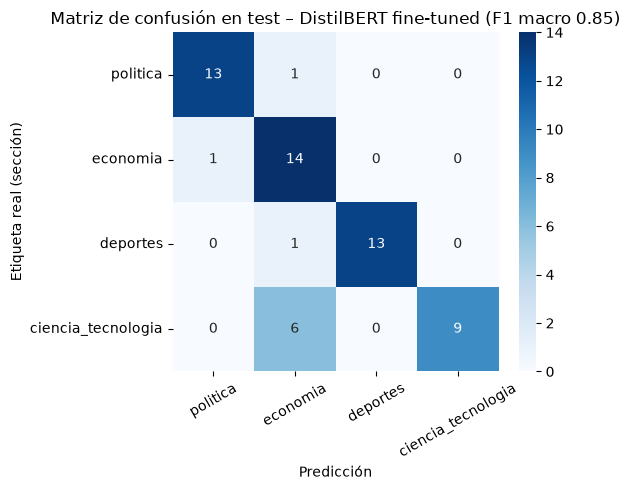

In [13]:
cm = confusion_matrix(y_true, y_ft, labels=CATS)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATS, yticklabels=CATS)
plt.title(f"Matriz de confusión en test – DistilBERT fine-tuned (F1 macro {f1_ft:.2f})")
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real (sección)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

In [14]:
f1_cat = pd.Series({c: reporte[c]["f1-score"] for c in CATS}).sort_values()
print(f"Mejor categoría: {f1_cat.idxmax()} (F1 {f1_cat.max():.3f}) | Peor: {f1_cat.idxmin()} (F1 {f1_cat.min():.3f})")
errores = test_df.assign(pred=y_ft).query("etiqueta != pred")[["titular", "etiqueta", "pred"]]
print(f"Errores en test: {len(errores)}")
errores

Mejor categoría: deportes (F1 0.963) | Peor: ciencia_tecnologia (F1 0.750)
Errores en test: 9


,titular,etiqueta,pred
371,Finlandia frena la construcción de dos centros de datos de Google por su impacto ambiental,ciencia_tecnologia,economia
312,YouTube planea incorporar audiolibros en 2027 y ya estaría en conversación con editoriales,ciencia_tecnologia,economia
290,Fenómeno El Niño Costero: ¿cuáles pueden ser las consecuencias para el Perú?,ciencia_tecnologia,economia
32,Keiko Fujimori anuncia coordinación con Delcy Rodríguez para expulsar a venezolanos indocumentados del Perú,politica,economia
330,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en ...,ciencia_tecnologia,economia
281,Adiós a las tarjetas amarillas y rojas: Uruguay ensaya un nuevo sistema para los árbitros,deportes,economia
363,“Ace Combat 8: Wings of Theve” eleva la franquicia a alturas insospechadas | Reseña,ciencia_tecnologia,economia
347,Informe Planeta Vivo 2026: la fauna silvestre cae 73% y América Latina es la región más golpeada (95 %),ciencia_tecnologia,economia
129,"‘OxI Exprés’: obras para enfrentar El Niño aún no tienen convenios suscritos, ¿por qué?",economia,politica


### Reflexión por categoría

_(reflexión pendiente)_

## 6. Comparativa y decisión

Los tres enfoques se evalúan sobre **el mismo conjunto de test** contra la etiqueta gold.

In [15]:
# Zero-shot y LLM sobre el mismo test (se vuelve a cargar el zero-shot, liberado en la sección 2)
zs = pipeline("zero-shot-classification", model=ZS_MODEL, device=DEVICE)
y_zs, _ = zero_shot(test_df["titular"])
y_llm = test_df["etiqueta_llm"].tolist()

# Latencia del modelo fine-tuned (1 titular por vez, como en el dashboard)
clf = pipeline("text-classification", model="modelo", tokenizer="modelo", device=DEVICE)
clf(test_df["titular"].iloc[0])
t0 = time.perf_counter()
for t in test_df["titular"][:30]:
    clf(t)
lat_ft = (time.perf_counter() - t0) / 30 * 1000

params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
comparativa = pd.DataFrame([
    {"modelo": "Zero-shot (BETO-XNLI)", "entrenamiento": "Ninguno", "entrada": "titular",
     "accuracy_test": accuracy_score(y_true, y_zs), "f1_macro_test": f1_score(y_true, y_zs, average="macro"),
     "latencia_ms": lat_zs, "parametros_M": params(zs.model)},
    {"modelo": "LLM débil (Qwen2.5-3B)", "entrenamiento": "Ninguno (prompt)", "entrada": "titular + bajada",
     "accuracy_test": accuracy_score(y_true, y_llm), "f1_macro_test": f1_score(y_true, y_llm, average="macro"),
     "latencia_ms": lat_llm, "parametros_M": params_llm},
    {"modelo": "DistilBERT fine-tuned", "entrenamiento": "3 épocas con etiquetas LLM", "entrada": "titular",
     "accuracy_test": acc_ft, "f1_macro_test": f1_ft, "latencia_ms": lat_ft, "parametros_M": params(trainer.model)},
]).round(3)
comparativa

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,modelo,entrenamiento,entrada,accuracy_test,f1_macro_test,latencia_ms,parametros_M
0,Zero-shot (BETO-XNLI),Ninguno,titular,0.655,0.641,40.179,109.853
1,LLM débil (Qwen2.5-3B),Ninguno (prompt),titular + bajada,0.862,0.859,1039.227,3085.939
2,DistilBERT fine-tuned,3 épocas con etiquetas LLM,titular,0.845,0.850,5.331,135.328


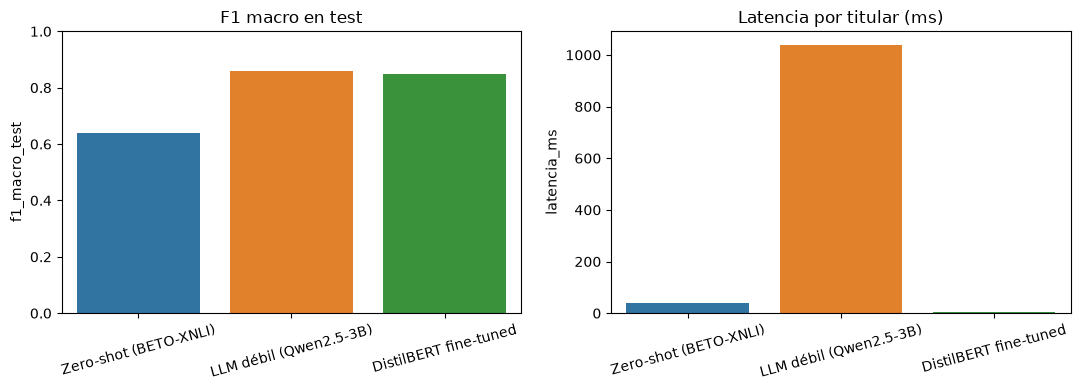

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=comparativa, x="modelo", y="f1_macro_test", ax=ax[0], hue="modelo", legend=False)
ax[0].set_title("F1 macro en test"); ax[0].set_ylim(0, 1); ax[0].tick_params(axis="x", rotation=15)
sns.barplot(data=comparativa, x="modelo", y="latencia_ms", ax=ax[1], hue="modelo", legend=False)
ax[1].set_title("Latencia por titular (ms)"); ax[1].tick_params(axis="x", rotation=15)
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.show()

In [17]:
# Métricas que usa el dashboard (archivo liviano, sí se versiona)
metricas = {
    "f1_macro_test": round(f1_ft, 4), "accuracy_test": round(acc_ft, 4), "n_test": len(y_true),
    "f1_zero_shot_40": round(f1_zs40, 4), "acc_zero_shot_40": round(acc_zs40, 4),
    "acuerdo_llm_humano": None if acuerdo_humano is None else round(acuerdo_humano, 4),
    "acuerdo_llm_humano_n": n_ok, "acuerdo_llm_seccion": round(acuerdo_seccion, 4),
    "comparativa": comparativa.to_dict(orient="records"),
    "modelo_base": FT_MODEL, "modelo_llm": LLM_MODEL, "fecha": date.today().isoformat(),
}
Path("modelo/metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

print("=" * 60)
print(f"F1 Macro (test): {f1_ft:.3f} | Zero-shot (40): {f1_zs40:.3f} | "
      f"Acuerdo LLM-Humano: {n_ok}/20" if n_ok is not None else "Auditoría pendiente")
print("=" * 60)

Auditoría pendiente


### Decisión para un entorno real

{DECISION}